# Detekcja Phishingu - SVM (Support Vector Machine)

Ten notebook zawiera implementację i analizę modelu SVM do wykrywania phishingu.

## 1. Import bibliotek i konfiguracja


In [ ]:
import sys
sys.path.append('..')

import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import importlib
import pickle
import concurrent.futures
import threading
from utils.feature_names import get_readable_name

from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Circle
from sklearn.inspection import permutation_importance
import matplotlib.patches as mpatches
from sklearn.model_selection import train_test_split

if 'utils.resource_monitor' in sys.modules:
    importlib.reload(sys.modules['utils.resource_monitor'])

from utils.resource_monitor import ResourceMonitor
from utils.feature_names import get_readable_name

from sklearn.svm import SVC, LinearSVC
from sklearn.model_selection import train_test_split, RandomizedSearchCV, cross_val_score, learning_curve, validation_curve
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                           roc_auc_score, confusion_matrix, roc_curve)
from scipy.stats import loguniform

import os
PLOTS_DIR = "../static/plots/svm"
MODELS_DIR = "../models/svm"
os.makedirs(PLOTS_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)

sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = 'white'
plt.rcParams['savefig.facecolor'] = 'white'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans']
plt.rcParams['font.size'] = 12
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 10
plt.rcParams['figure.titlesize'] = 16
plt.rcParams['figure.figsize'] = (12, 7)

np.random.seed(42)

print("Biblioteki zostały zaimportowane pomyślnie!")


Biblioteki zostały zaimportowane pomyślnie!


## 2. Wczytanie i eksploracja danych (oba zbiory)


In [2]:
df_original = pd.read_csv('../data/dataset_full.csv')
df_optimized = pd.read_csv('../data/dataset_optimized.csv')

datasets = {
    'Pełny zbiór': df_original,
    'Zoptymalizowany zbiór': df_optimized
}

print("="*60)
print("PORÓWNANIE ZBIORÓW DANYCH")
print("="*60)

for name, df in datasets.items():
    print(f"\n{'='*60}")
    print(f"Zbiór: {name.upper()}")
    print(f"{'='*60}")
    print(f"Rozmiar zbioru: {df.shape}")
    print(f"Liczba cech: {len(df.columns)-1}")

    print(f"\nPierwsze 5 kolumn: {list(df.columns[:5])}")
    print(f"Ostatnie 5 kolumn: {list(df.columns[-5:])}")

    label_counts = df['phishing'].value_counts()
    print(f"\nRozkład etykiet:")
    print(f"URL oznaczone jako bezpieczne: {label_counts[0]:,} ({label_counts[0]/len(df)*100:.1f}%)")
    print(f"URL oznaczone jako phisingowe: {label_counts[1]:,} ({label_counts[1]/len(df)*100:.1f}%)")

    print(f"\nInformacje o zbiorze:")
    print(f"- Łączna liczba próbek: {len(df):,}")
    print(f"- Liczba cech: {len(df.columns)-1}")
    print(f"- Brakujące wartości: {df.isnull().sum().sum()}")
    print(f"- Duplikaty: {df.duplicated().sum()}")


PORÓWNANIE ZBIORÓW DANYCH

Zbiór: PEŁNY ZBIÓR
Rozmiar zbioru: (88647, 112)
Liczba cech: 111

Pierwsze 5 kolumn: ['qty_dot_url', 'qty_hyphen_url', 'qty_underline_url', 'qty_slash_url', 'qty_questionmark_url']
Ostatnie 5 kolumn: ['qty_redirects', 'url_google_index', 'domain_google_index', 'url_shortened', 'phishing']

Rozkład etykiet:
URL oznaczone jako bezpieczne: 58,000 (65.4%)
URL oznaczone jako phisingowe: 30,647 (34.6%)

Informacje o zbiorze:
- Łączna liczba próbek: 88,647
- Liczba cech: 111
- Brakujące wartości: 0
- Duplikaty: 1438

Zbiór: ZOPTYMALIZOWANY ZBIÓR
Rozmiar zbioru: (87209, 75)
Liczba cech: 74

Pierwsze 5 kolumn: ['qty_dot_url', 'qty_hyphen_url', 'qty_underline_url', 'qty_slash_url', 'qty_questionmark_url']
Ostatnie 5 kolumn: ['ttl_hostname', 'tls_ssl_certificate', 'qty_redirects', 'url_shortened', 'phishing']

Rozkład etykiet:
URL oznaczone jako bezpieczne: 56,712 (65.0%)
URL oznaczone jako phisingowe: 30,497 (35.0%)

Informacje o zbiorze:
- Łączna liczba próbek: 87,209

## 3. Przygotowanie cech i etykiet (dla obu zbiorów)


In [3]:
data_splits = {}

for name, df in datasets.items():
    X = df.iloc[:, :-1]
    y = df.iloc[:, -1]

    print(f"\n{'='*60}")
    print(f"Przygotowanie danych: {name.upper()}")
    print(f"{'='*60}")
    print(f"  Liczba cech: {X.shape[1]}")
    print(f"  Liczba próbek: {X.shape[0]:,}")

    print(f"\nRozkład klas:")
    for label, count in y.value_counts().items():
        percentage = count / len(y) * 100
        label_name = "Brak Phishingu" if label == 0 else "Phishing"
        print(f"  {label} ({label_name}): {count:,} ({percentage:.1f}%)")

    data_splits[name] = {
        'X': X,
        'y': y
    }


Przygotowanie danych: PEŁNY ZBIÓR
  Liczba cech: 111
  Liczba próbek: 88,647

Rozkład klas:
  0 (Brak Phishingu): 58,000 (65.4%)
  1 (Phishing): 30,647 (34.6%)

Przygotowanie danych: ZOPTYMALIZOWANY ZBIÓR
  Liczba cech: 74
  Liczba próbek: 87,209

Rozkład klas:
  0 (Brak Phishingu): 56,712 (65.0%)
  1 (Phishing): 30,497 (35.0%)


## 4. Podział danych i standaryzacja (dla obu zbiorów)


In [4]:
for name in data_splits.keys():
    X = data_splits[name]['X']
    y = data_splits[name]['y']

    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )

    print(f"\n{'='*60}")
    print(f"Podział danych: {name.upper()}")
    print(f"{'='*60}")
    print(f"Zbiór uczący: {X_train.shape[0]:,} próbek ({X_train.shape[0]/len(X)*100:.1f}%)")
    print(f"Zbiór testowy: {X_test.shape[0]:,} próbek ({X_test.shape[0]/len(X)*100:.1f}%)")

    print(f"\nRozkład klas w zbiorze uczącym:")
    train_counts = y_train.value_counts()
    print(f"  Brak phishingu: {train_counts[0]:,} ({train_counts[0]/len(y_train)*100:.1f}%)")
    print(f"  Phishing: {train_counts[1]:,} ({train_counts[1]/len(y_train)*100:.1f}%)")

    print(f"\nRozkład klas w zbiorze testowym:")
    test_counts = y_test.value_counts()
    print(f"  Brak phishingu: {test_counts[0]:,} ({test_counts[0]/len(y_test)*100:.1f}%)")
    print(f"  Phishing: {test_counts[1]:,} ({test_counts[1]/len(y_test)*100:.1f}%)")

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    print(f"\nStatystyki cech po skalowaniu (zbiór uczący):")
    print(f"  Średnia: {X_train_scaled.mean():.6f}")
    print(f"  Odchylenie standardowe: {X_train_scaled.std():.6f}")
    print(f"  Minimum: {X_train_scaled.min():.4f}")
    print(f"  Maksimum: {X_train_scaled.max():.4f}")

    data_splits[name]['X_train'] = X_train
    data_splits[name]['X_test'] = X_test
    data_splits[name]['y_train'] = y_train
    data_splits[name]['y_test'] = y_test
    data_splits[name]['X_train_scaled'] = X_train_scaled
    data_splits[name]['X_test_scaled'] = X_test_scaled
    data_splits[name]['scaler'] = scaler


Podział danych: PEŁNY ZBIÓR
Zbiór uczący: 70,917 próbek (80.0%)
Zbiór testowy: 17,730 próbek (20.0%)

Rozkład klas w zbiorze uczącym:
  Brak phishingu: 46,400 (65.4%)
  Phishing: 24,517 (34.6%)

Rozkład klas w zbiorze testowym:
  Brak phishingu: 11,600 (65.4%)
  Phishing: 6,130 (34.6%)

Statystyki cech po skalowaniu (zbiór uczący):
  Średnia: 0.000000
  Odchylenie standardowe: 0.939618
  Minimum: -17.1120
  Maksimum: 266.3006

Podział danych: ZOPTYMALIZOWANY ZBIÓR
Zbiór uczący: 69,767 próbek (80.0%)
Zbiór testowy: 17,442 próbek (20.0%)

Rozkład klas w zbiorze uczącym:
  Brak phishingu: 45,369 (65.0%)
  Phishing: 24,398 (35.0%)

Rozkład klas w zbiorze testowym:
  Brak phishingu: 11,343 (65.0%)
  Phishing: 6,099 (35.0%)

Statystyki cech po skalowaniu (zbiór uczący):
  Średnia: -0.000000
  Odchylenie standardowe: 1.000000
  Minimum: -4.1315
  Maksimum: 142.8770


## 5. Optymalizacja hiperparametrów i uczenie modeli (dla obu zbiorów)


In [5]:
def train_model_for_dataset(dataset_name):
    print(f"[{threading.current_thread().name}] Rozpoczynanie treningu dla: {dataset_name.upper()}")

    X_train_scaled = data_splits[dataset_name]['X_train_scaled']
    y_train = data_splits[dataset_name]['y_train']

    SAMPLE_SIZE = 20000
    if len(X_train_scaled) > SAMPLE_SIZE:
        print(f"[{threading.current_thread().name}] Tworzenie podpróbki ({SAMPLE_SIZE}) dla jądra RBF...")
        from sklearn.model_selection import train_test_split
        X_train_sampled, _, y_train_sampled, _ = train_test_split(
            X_train_scaled, y_train,
            train_size=SAMPLE_SIZE,
            random_state=42,
            stratify=y_train
        )
    else:
        X_train_sampled, y_train_sampled = X_train_scaled, y_train

    param_grids = [
        {
            'name': 'LinearSVC (Szybka optymalizacja liniowa)',
            'estimator': LinearSVC(random_state=42, dual=False, max_iter=2000),
            'params': {'C': loguniform(1e-3, 1e3)},
            'n_iter': 20,
            'X_train': X_train_scaled,
            'y_train': y_train
        },
        {
            'name': 'SVC with RBF Kernel (Randomized Search on Sample)',
            'estimator': SVC(random_state=42, probability=True, kernel='rbf', cache_size=1000),
            'params': {'C': loguniform(1, 1000), 'gamma': loguniform(1e-4, 1e-1)},
            'n_iter': 10,
            'X_train': X_train_sampled,
            'y_train': y_train_sampled
        }
    ]

    best_overall_score = 0
    best_overall_model = None
    best_overall_params = None
    best_config_name = ""
    start_time = time.time()

    for i, grid_config in enumerate(param_grids):
        config_name = grid_config['name']
        param_grid = grid_config['params']
        estimator = grid_config['estimator']
        n_iter = grid_config['n_iter']
        X_train_current = grid_config['X_train']
        y_train_current = grid_config['y_train']

        print(f"\n[{threading.current_thread().name}] {'='*60}")
        print(f"Konfiguracja {i+1}/{len(param_grids)}: {config_name}")
        print(f"Rozmiar zbioru treningowego: {len(X_train_current):,}")
        print(f"{'='*60}")

        config_start_time = time.time()
        random_search = RandomizedSearchCV(
            estimator=estimator,
            param_distributions=param_grid,
            n_iter=n_iter,
            cv=5,
            scoring='roc_auc',
            n_jobs=-1,
            verbose=1,
            random_state=42
        )
        random_search.fit(X_train_current, y_train_current)
        config_time = time.time() - config_start_time

        print(f"[{threading.current_thread().name}] Najlepszy CV ROC-AUC: {random_search.best_score_:.4f} (czas: {config_time:.2f}s)")

        if random_search.best_score_ > best_overall_score:
            best_overall_score = random_search.best_score_
            best_overall_model = random_search.best_estimator_
            best_overall_params = random_search.best_params_
            best_config_name = config_name

    total_time = time.time() - start_time
    print(f"\n[{threading.current_thread().name}] Podsumowanie optymalizacji dla {dataset_name}:")
    print(f"  Całkowity czas: {total_time:.2f}s, Najlepszy CV ROC-AUC: {best_overall_score:.4f}")

    print(f"[{threading.current_thread().name}] Trenowanie finalnego modelu...")
    resource_monitor = ResourceMonitor(interval=0.1, debug=False)
    resource_monitor.start()

    best_overall_model.fit(X_train_scaled, y_train)

    resource_monitor.stop()
    stats = resource_monitor.get_stats()

    print(f"[{threading.current_thread().name}] Zakończono trening dla: {dataset_name.upper()}")

    return dataset_name, {
        'model': best_overall_model,
        'best_params': best_overall_params,
        'best_score': best_overall_score,
        'best_config_name': best_config_name,
        'training_time': total_time,
        'resource_monitor': resource_monitor,
        'resource_stats': stats,
        'X_train_scaled': X_train_scaled,
        'X_test_scaled': data_splits[dataset_name]['X_test_scaled'],
        'y_train': y_train,
        'y_test': data_splits[dataset_name]['y_test']
    }

results_for_datasets = {}
dataset_names = ['Pełny zbiór', 'Zoptymalizowany zbiór']

with concurrent.futures.ThreadPoolExecutor(max_workers=len(dataset_names), thread_name_prefix='SVM_Trainer') as executor:
    future_to_dataset = {executor.submit(train_model_for_dataset, name): name for name in dataset_names}

    for future in concurrent.futures.as_completed(future_to_dataset):
        dataset_name = future_to_dataset[future]
        try:
            name, result_data = future.result()
            results_for_datasets[name] = result_data
        except Exception as exc:
            print(f'{dataset_name} wygenerował wyjątek: {exc}')

print(f"\n{'='*80}")
print("ZAKOŃCZONO RÓWNOLEGŁE TRENOWANIE MODELI DLA OBU ZBIORÓW")
print(f"{'='*80}")

[SVM_Trainer_0] Rozpoczynanie treningu dla: PEŁNY ZBIÓR[SVM_Trainer_1] Rozpoczynanie treningu dla: ZOPTYMALIZOWANY ZBIÓR
[SVM_Trainer_1] Tworzenie podpróbki (20000) dla jądra RBF...

[SVM_Trainer_0] Tworzenie podpróbki (20000) dla jądra RBF...

[SVM_Trainer_1] ============================================================
Konfiguracja 1/2: LinearSVC (Szybka optymalizacja liniowa)
Rozmiar zbioru treningowego: 69,767
Fitting 5 folds for each of 20 candidates, totalling 100 fits

[SVM_Trainer_0] ============================================================
Konfiguracja 1/2: LinearSVC (Szybka optymalizacja liniowa)
Rozmiar zbioru treningowego: 70,917
Fitting 5 folds for each of 20 candidates, totalling 100 fits
[SVM_Trainer_1] Najlepszy CV ROC-AUC: 0.9786 (czas: 85.25s)

[SVM_Trainer_1] ============================================================
Konfiguracja 2/2: SVC with RBF Kernel (Randomized Search on Sample)
Rozmiar zbioru treningowego: 20,000
Fitting 5 folds for each of 10 candidates, t

## 5.1. Trening i monitorowanie zasobów systemowych (RAM i CPU)


In [6]:
results_with_monitoring = {}

for dataset_name in ['Pełny zbiór', 'Zoptymalizowany zbiór']:
    print(f"\n{'='*80}")
    print(f"TRENING Z MONITOROWANIEM ZASOBÓW - {dataset_name.upper()}")
    print(f"{'='*80}")

    X_train_scaled = data_splits[dataset_name]['X_train_scaled']
    X_test_scaled = data_splits[dataset_name]['X_test_scaled']
    y_train = data_splits[dataset_name]['y_train']
    y_test = data_splits[dataset_name]['y_test']
    best_params = results_for_datasets[dataset_name]['best_params']

    print(f"Trenowanie na pełnym zbiorze uczącym: {X_train_scaled.shape[0]:,} próbek, {X_train_scaled.shape[1]} cech")
    print(f"Parametry modelu: {best_params}")

    resource_monitor = ResourceMonitor(interval=0.1, debug=False)
    resource_monitor.start()

    training_start = time.time()
    best_model = SVC(random_state=42, probability=True, **best_params)
    best_model.fit(X_train_scaled, y_train)
    training_time = time.time() - training_start

    resource_monitor.stop()

    stats = resource_monitor.get_stats()

    results_with_monitoring[dataset_name] = {
        'model': best_model,
        'training_time': training_time,
        'resource_monitor': resource_monitor,
        'resource_stats': stats
    }

    if stats:
        print(f"\nWYNIKI MONITOROWANIA:")
        print(f"  • Czas treningu: {training_time:.2f}s")
        print(f"  • Liczba próbek monitorowania: {stats['samples']}")
        print(f"  • CPU:")
        print(f"    - Min: {stats['cpu']['min']:.1f}%")
        print(f"    - Max: {stats['cpu']['max']:.1f}%")
        print(f"    - Średnia: {stats['cpu']['mean']:.1f}%")
        print(f"  • RAM:")
        print(f"    - Min: {stats['ram']['min']:.2f} GB")
        print(f"    - Max: {stats['ram']['max']:.2f} GB")
        print(f"    - Średnia: {stats['ram']['mean']:.2f} GB")

print(f"\n{'='*80}")
print("ZAKOŃCZONO TRENOWANIE MODELI Z MONITOROWANIEM DLA OBU ZBIORÓW")
print(f"{'='*80}")


TRENING Z MONITOROWANIEM ZASOBÓW - PEŁNY ZBIÓR
Trenowanie na pełnym zbiorze uczącym: 70,917 próbek, 111 cech
Parametry modelu: {'C': np.float64(63.583588566762494), 'gamma': np.float64(0.013311216080736894)}

WYNIKI MONITOROWANIA:
  • Czas treningu: 1014.62s
  • Liczba próbek monitorowania: 9342
  • CPU:
    - Min: 0.0%
    - Max: 10.2%
    - Średnia: 9.4%
  • RAM:
    - Min: 1.61 GB
    - Max: 2.54 GB
    - Średnia: 1.90 GB

TRENING Z MONITOROWANIEM ZASOBÓW - ZOPTYMALIZOWANY ZBIÓR
Trenowanie na pełnym zbiorze uczącym: 69,767 próbek, 74 cech
Parametry modelu: {'C': np.float64(63.583588566762494), 'gamma': np.float64(0.013311216080736894)}

WYNIKI MONITOROWANIA:
  • Czas treningu: 626.84s
  • Liczba próbek monitorowania: 5789
  • CPU:
    - Min: 0.0%
    - Max: 10.1%
    - Średnia: 9.4%
  • RAM:
    - Min: 1.38 GB
    - Max: 1.69 GB
    - Średnia: 1.54 GB

ZAKOŃCZONO TRENOWANIE MODELI Z MONITOROWANIEM DLA OBU ZBIORÓW


## 5.2. Wizualizacja wykorzystania zasobów systemowych


In [7]:
print(f"\n{'='*80}")
print("SZCZEGÓŁOWE STATYSTYKI WYKORZYSTANIA ZASOBÓW")
print(f"{'='*80}")

dataset_display_names = {
    'Pełny zbiór': 'Pełny zbiór (111 cech)',
    'Zoptymalizowany zbiór': 'Zoptymalizowany zbiór (73 cechy)'
}

for dataset_name in ['Pełny zbiór', 'Zoptymalizowany zbiór']:
    stats = results_for_datasets[dataset_name]['resource_stats']
    training_time = results_for_datasets[dataset_name]['training_time']
    display_name = dataset_display_names[dataset_name]

    if stats:
        print(f"\n{display_name}:")
        print(f"  • Czas treningu: {training_time:.2f}s")
        print(f"  • Liczba próbek: {stats['samples']}")
        print(f"  • CPU:")
        print(f"    - Min: {stats['cpu']['min']:.1f}%")
        print(f"    - Max: {stats['cpu']['max']:.1f}%")
        print(f"    - Średnia: {stats['cpu']['mean']:.1f}%")
        print(f"  • RAM:")
        print(f"    - Min: {stats['ram']['min']:.2f} GB")
        print(f"    - Max: {stats['ram']['max']:.2f} GB")
        print(f"    - Średnia: {stats['ram']['mean']:.2f} GB")


SZCZEGÓŁOWE STATYSTYKI WYKORZYSTANIA ZASOBÓW

Pełny zbiór (111 cech):
  • Czas treningu: 615.01s
  • Liczba próbek: 5020
  • CPU:
    - Min: 0.0%
    - Max: 19.8%
    - Średnia: 15.9%
  • RAM:
    - Min: 2.31 GB
    - Max: 3.12 GB
    - Średnia: 2.61 GB

Zoptymalizowany zbiór (73 cechy):
  • Czas treningu: 602.56s
  • Liczba próbek: 3577
  • CPU:
    - Min: 0.0%
    - Max: 19.9%
    - Średnia: 18.9%
  • RAM:
    - Min: 2.44 GB
    - Max: 3.60 GB
    - Średnia: 2.70 GB


## 5.2. Wizualizacja wykorzystania zasobów systemowych


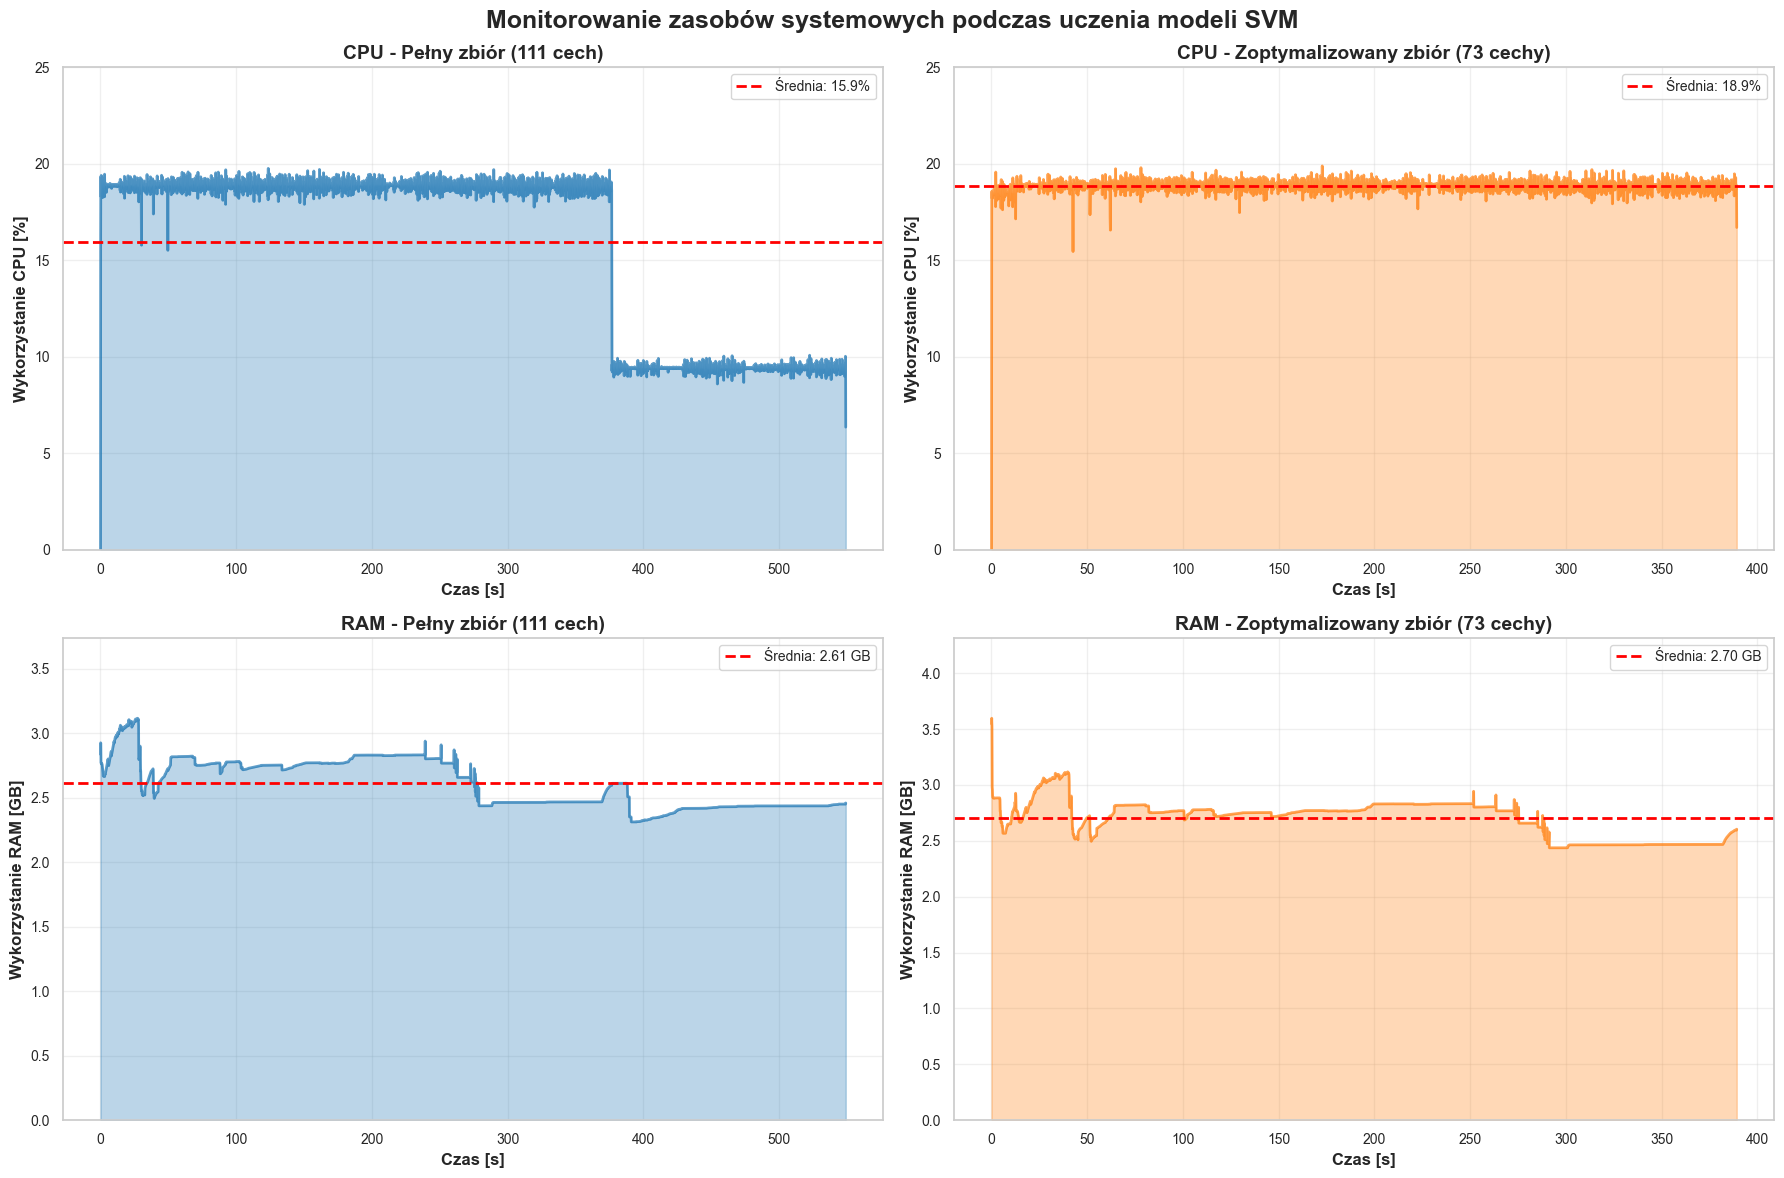

✅ Wizualizacja wykorzystania zasobów zapisana


In [19]:
fig, axes = plt.subplots(2, 2, figsize=(18, 12))
fig.suptitle('Monitorowanie zasobów systemowych podczas uczenia modeli SVM', fontsize=18, fontweight='bold')

dataset_names = ['Pełny zbiór', 'Zoptymalizowany zbiór']
dataset_display_names_list = ['Pełny zbiór (111 cech)', 'Zoptymalizowany zbiór (73 cechy)']
colors = ['#1f77b4', '#ff7f0e']

for idx, dataset_name in enumerate(dataset_names):
    monitor = results_for_datasets[dataset_name]['resource_monitor']
    stats = results_for_datasets[dataset_name]['resource_stats']
    display_name = dataset_display_names_list[idx]

    if stats and len(monitor.timestamps) > 0:
        time_array = np.array(monitor.timestamps)
        cpu_array = np.array(monitor.cpu_percent)
        ram_array = np.array(monitor.ram_gb)

        axes[0, idx].plot(time_array, cpu_array, color=colors[idx], linewidth=2, alpha=0.7)
        axes[0, idx].axhline(y=stats['cpu']['mean'], color='red', linestyle='--',
                            linewidth=2, label=f'Średnia: {stats["cpu"]["mean"]:.1f}%')
        axes[0, idx].fill_between(time_array, cpu_array, alpha=0.3, color=colors[idx])
        axes[0, idx].set_xlabel('Czas [s]', fontsize=12, fontweight='bold')
        axes[0, idx].set_ylabel('Wykorzystanie CPU [%]', fontsize=12, fontweight='bold')
        axes[0, idx].set_title(f'CPU - {display_name}', fontweight='bold', fontsize=14)
        axes[0, idx].legend(fontsize=10)
        axes[0, idx].grid(True, alpha=0.3)
        axes[0, idx].set_ylim([0, max(25, stats['cpu']['max'] * 1.1)])

        axes[1, idx].plot(time_array, ram_array, color=colors[idx], linewidth=2, alpha=0.7)
        axes[1, idx].axhline(y=stats['ram']['mean'], color='red', linestyle='--',
                            linewidth=2, label=f'Średnia: {stats["ram"]["mean"]:.2f} GB')
        axes[1, idx].fill_between(time_array, ram_array, alpha=0.3, color=colors[idx])
        axes[1, idx].set_xlabel('Czas [s]', fontsize=12, fontweight='bold')
        axes[1, idx].set_ylabel('Wykorzystanie RAM [GB]', fontsize=12, fontweight='bold')
        axes[1, idx].set_title(f'RAM - {display_name}', fontweight='bold', fontsize=14)
        axes[1, idx].legend(fontsize=10)
        axes[1, idx].grid(True, alpha=0.3)
        axes[1, idx].set_ylim([0, stats['ram']['max'] * 1.2])

plt.tight_layout()
plt.savefig(f'{PLOTS_DIR}/svm_resource_usage_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Wizualizacja wykorzystania zasobów zapisana")

## 6. Ewaluacja modeli (dla obu zbiorów)


In [9]:
evaluation_results = {}

for dataset_name in ['Pełny zbiór', 'Zoptymalizowany zbiór']:
    print(f"\n{'='*80}")
    print(f"EWALUACJA MODELU - {dataset_name.upper()}")
    print(f"{'='*80}")

    model = results_for_datasets[dataset_name]['model']
    X_train = results_for_datasets[dataset_name]['X_train_scaled']
    X_test = results_for_datasets[dataset_name]['X_test_scaled']
    y_train = results_for_datasets[dataset_name]['y_train']
    y_test = results_for_datasets[dataset_name]['y_test']

    y_pred = model.predict(X_test)
    y_pred_proba = model.predict_proba(X_test)[:, 1]

    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc_roc = roc_auc_score(y_test, y_pred_proba)

    cv_scores = cross_val_score(model, X_train, y_train, cv=5, scoring='roc_auc')

    evaluation_results[dataset_name] = {
        'y_pred': y_pred,
        'y_pred_proba': y_pred_proba,
        'confusion_matrix': cm,
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'auc_roc': auc_roc,
        'cv_scores': cv_scores,
        'cv_mean': cv_scores.mean(),
        'cv_std': cv_scores.std()
    }

    print(f"\nWYNIKI NA ZBIORZE TESTOWYM:")
    print(f"  • Dokładność (Accuracy): {accuracy:.4f}")
    print(f"  • Precyzja (Precision): {precision:.4f}")
    print(f"  • Czułość (Recall): {recall:.4f}")
    print(f"  • Miara F1 (F1-Score): {f1:.4f}")
    print(f"  • AUC-ROC: {auc_roc:.4f}")

    print(f"\nMACIERZ POMYŁEK:")
    print(f"  • Prawdziwie negatywne (TN): {tn:,}")
    print(f"  • Fałszywie pozytywne (FP): {fp:,}")
    print(f"  • Fałszywie negatywne (FN): {fn:,}")
    print(f"  • Prawdziwie pozytywne (TP): {tp:,}")

    print(f"\nPIĘCIOKROTNA WALIDACJA KRZYŻOWA:")
    print(f"  • Średni wynik ROC-AUC: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")
    print(f"  • Min: {cv_scores.min():.4f}")
    print(f"  • Max: {cv_scores.max():.4f}")

print(f"\n{'='*80}")
print("PORÓWNANIE WYNIKÓW")
print(f"{'='*80}")
print(f"{'Metryka':<20} {'Pełny zbiór':>15} {'Zoptymalizowany zbiór':>20}")
print(f"{'-'*80}")
for metric in ['accuracy', 'precision', 'recall', 'f1', 'auc_roc']:
    full_val = evaluation_results['Pełny zbiór'][metric]
    opt_val = evaluation_results['Zoptymalizowany zbiór'][metric]
    diff = opt_val - full_val
    diff_str = f"({diff:+.4f})" if diff != 0 else ""
    print(f"{metric.capitalize():<20} {full_val:>15.4f} {opt_val:>15.4f} {diff_str:>5}")


EWALUACJA MODELU - PEŁNY ZBIÓR

WYNIKI NA ZBIORZE TESTOWYM:
  • Dokładność (Accuracy): 0.9603
  • Precyzja (Precision): 0.9477
  • Czułość (Recall): 0.9370
  • Miara F1 (F1-Score): 0.9423
  • AUC-ROC: 0.9884

MACIERZ POMYŁEK:
  • Prawdziwie negatywne (TN): 11,283
  • Fałszywie pozytywne (FP): 317
  • Fałszywie negatywne (FN): 386
  • Prawdziwie pozytywne (TP): 5,744

PIĘCIOKROTNA WALIDACJA KRZYŻOWA:
  • Średni wynik ROC-AUC: 0.9881 ± 0.0005
  • Min: 0.9875
  • Max: 0.9891

EWALUACJA MODELU - ZOPTYMALIZOWANY ZBIÓR

WYNIKI NA ZBIORZE TESTOWYM:
  • Dokładność (Accuracy): 0.9602
  • Precyzja (Precision): 0.9482
  • Czułość (Recall): 0.9372
  • Miara F1 (F1-Score): 0.9427
  • AUC-ROC: 0.9878

MACIERZ POMYŁEK:
  • Prawdziwie negatywne (TN): 11,031
  • Fałszywie pozytywne (FP): 312
  • Fałszywie negatywne (FN): 383
  • Prawdziwie pozytywne (TP): 5,716

PIĘCIOKROTNA WALIDACJA KRZYŻOWA:
  • Średni wynik ROC-AUC: 0.9882 ± 0.0007
  • Min: 0.9870
  • Max: 0.9891

PORÓWNANIE WYNIKÓW
Metryka       

## 7. Wizualizacja kompleksowa i krzywa uczenia


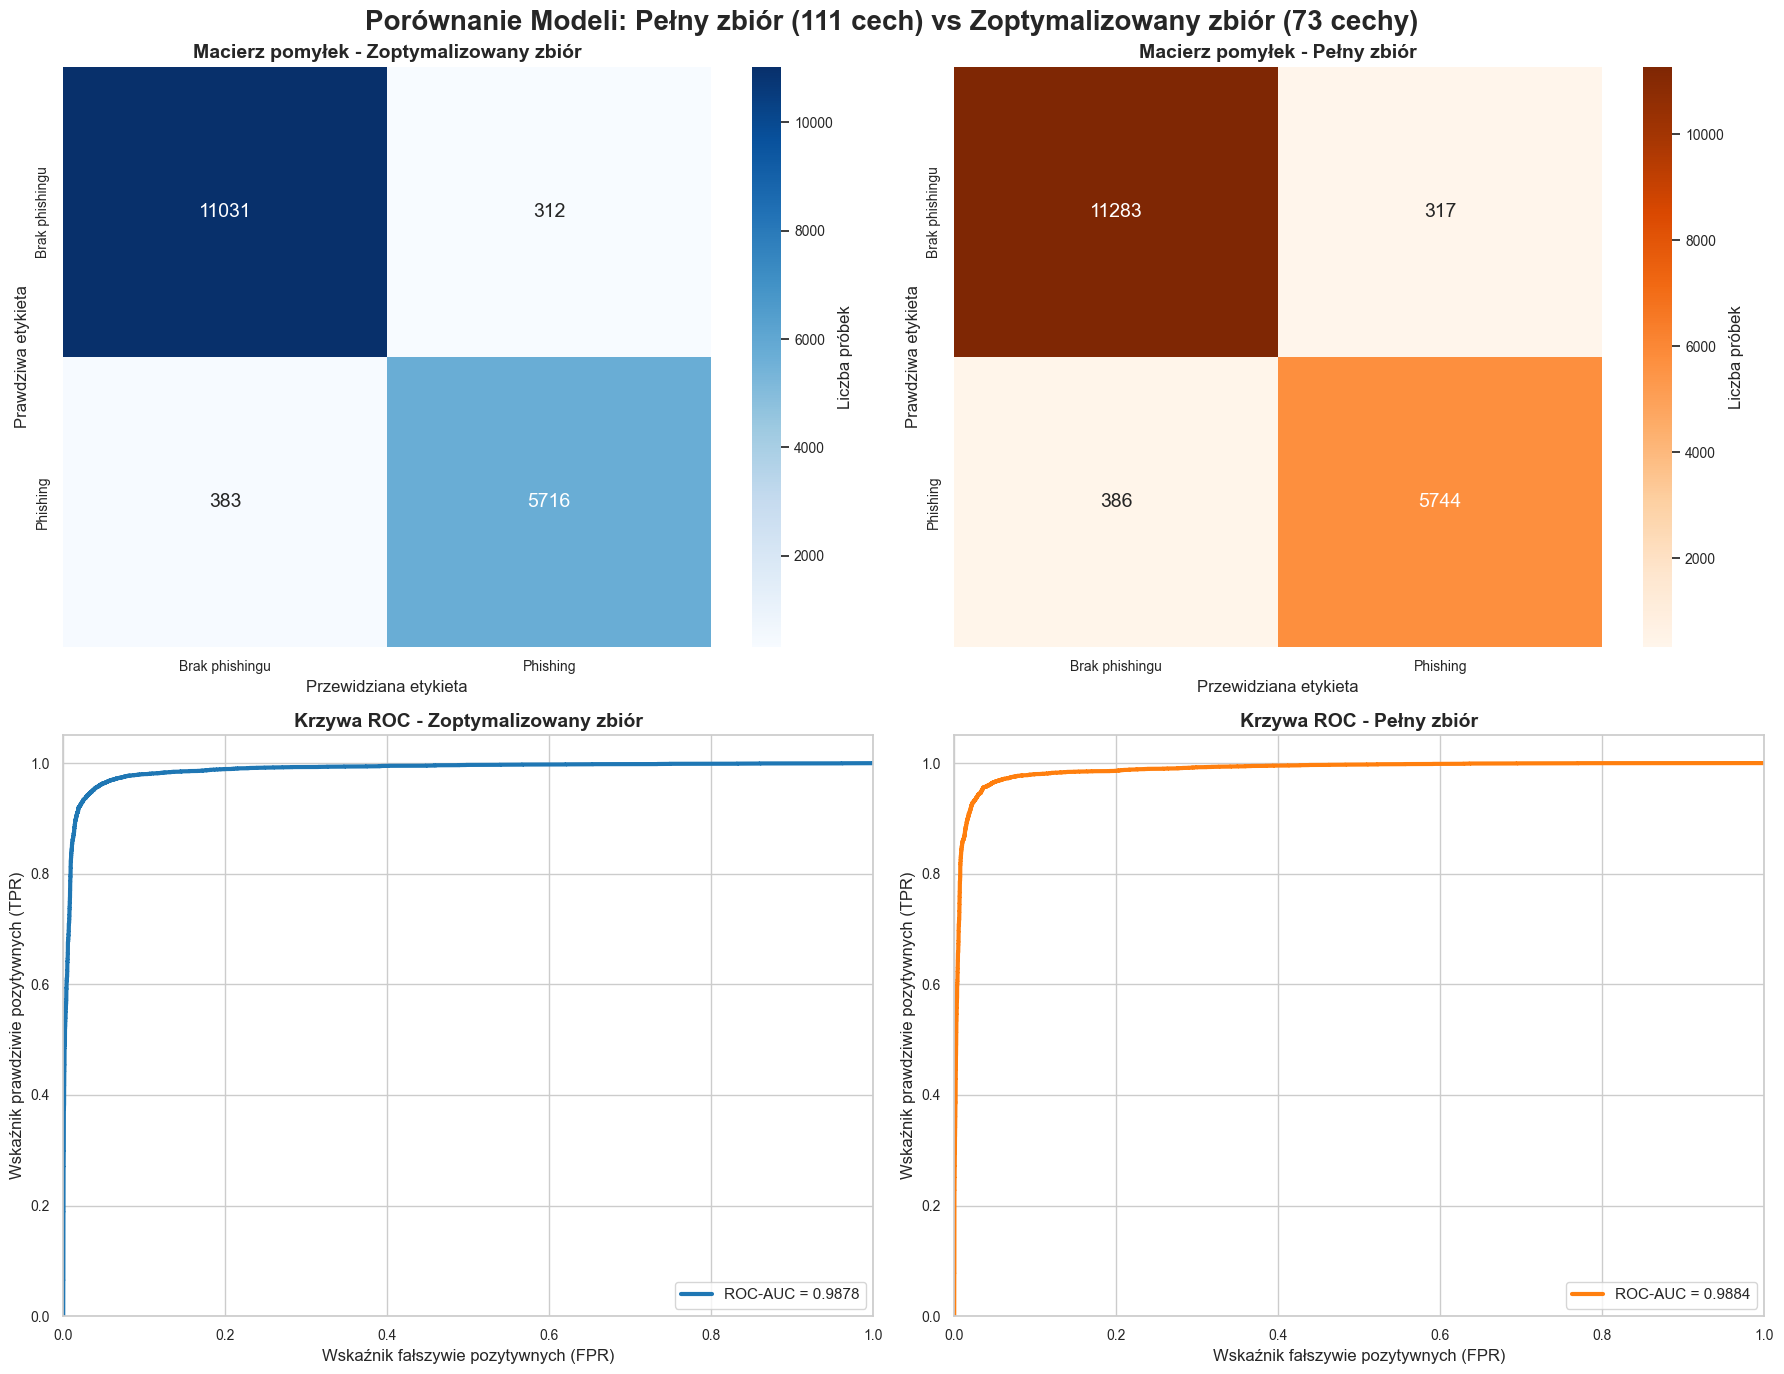

✅ Wizualizacja porównawcza zapisana


In [10]:
dataset_mapping = {
    'Pełny zbiór': 'Pełny zbiór',
    'Zoptymalizowany zbiór': 'Zoptymalizowany zbiór'
}

renamed_trained_models = {dataset_mapping[k]: v for k, v in results_for_datasets.items()}
renamed_evaluation_results = {dataset_mapping[k]: v for k, v in evaluation_results.items()}
renamed_train_test_data = {
    'Pełny zbiór': {
        'X_train': data_splits['Pełny zbiór']['X'],
        'y_test': data_splits['Pełny zbiór']['y_test']
    },
    'Zoptymalizowany zbiór': {
        'X_train': data_splits['Zoptymalizowany zbiór']['X'],
        'y_test': data_splits['Zoptymalizowany zbiór']['y_test']
    }
}

fig, axes = plt.subplots(2, 2, figsize=(18, 14))
fig.suptitle('Porównanie Modeli: Pełny zbiór (111 cech) vs Zoptymalizowany zbiór (73 cechy)', fontsize=20, fontweight='bold')

dataset_names = list(renamed_trained_models.keys())
colors = ['#1f77b4', '#ff7f0e']

for idx, dataset_name in enumerate(dataset_names):
    cm = renamed_evaluation_results[dataset_name]['confusion_matrix']
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues' if idx == 0 else 'Oranges',
                xticklabels=['Brak phishingu', 'Phishing'],
                yticklabels=['Brak phishingu', 'Phishing'],
                ax=axes[0, idx], annot_kws={"size": 14}, cbar_kws={'label': 'Liczba próbek'})
    axes[0, idx].set_title(f'Macierz pomyłek - {dataset_name}', fontweight='bold', fontsize=14)
    axes[0, idx].set_ylabel('Prawdziwa etykieta')
    axes[0, idx].set_xlabel('Przewidziana etykieta')

for idx, dataset_name in enumerate(dataset_names):
    y_test = renamed_train_test_data[dataset_name]['y_test']
    y_pred_proba = renamed_evaluation_results[dataset_name]['y_pred_proba']
    auc_roc = renamed_evaluation_results[dataset_name]['auc_roc']

    fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
    axes[1, idx].plot(fpr, tpr, color=colors[idx], lw=3, label=f'ROC-AUC = {auc_roc:.4f}')
    axes[1, idx].set_xlim([0.0, 1.0])
    axes[1, idx].set_ylim([0.0, 1.05])
    axes[1, idx].set_xlabel('Wskaźnik fałszywie pozytywnych (FPR)', fontsize=12)
    axes[1, idx].set_ylabel('Wskaźnik prawdziwie pozytywnych (TPR)', fontsize=12)
    axes[1, idx].set_title(f'Krzywa ROC - {dataset_name}', fontweight='bold', fontsize=14)
    axes[1, idx].legend(loc="lower right", fontsize=11)

plt.tight_layout()
plt.savefig(f'{PLOTS_DIR}/svm_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Wizualizacja porównawcza zapisana")

## 7.1. Porównanie metryk w postaci wykresów słupkowych


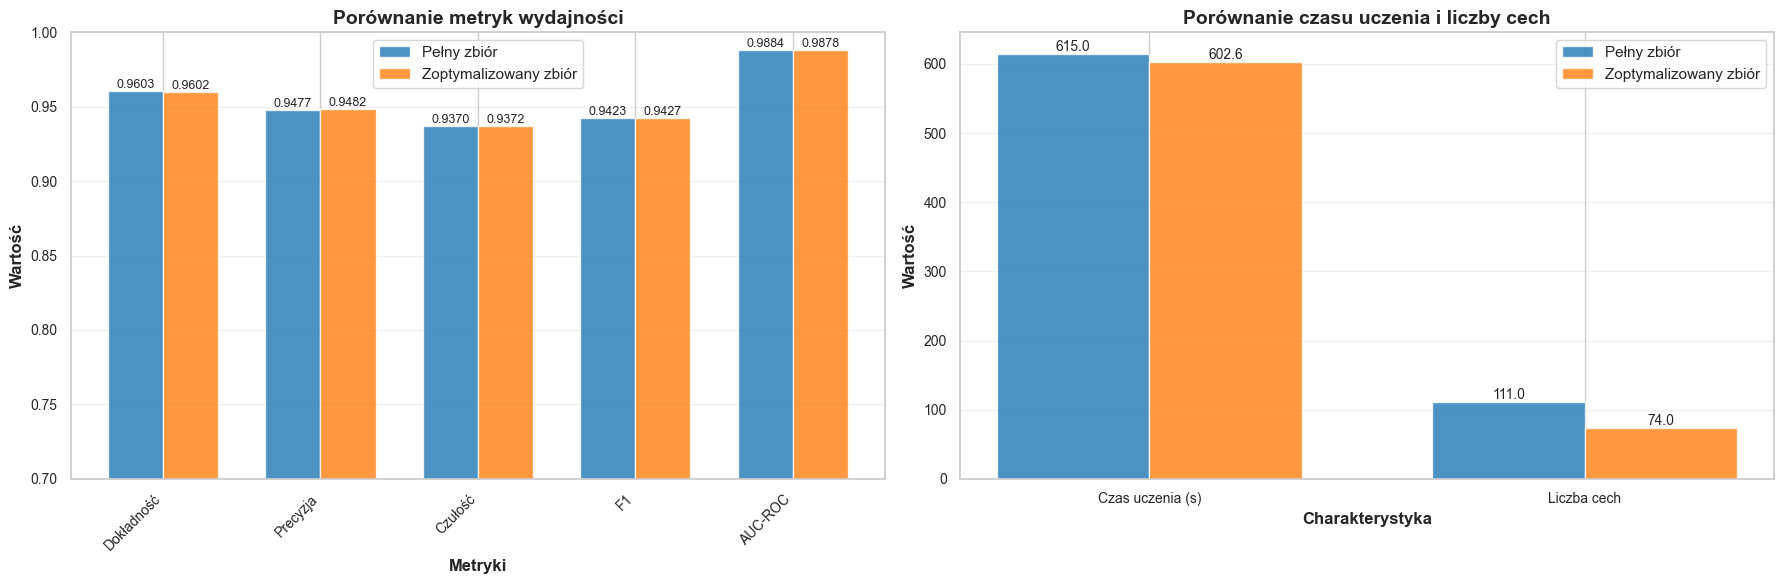

✅ Wizualizacja metryk zapisana
✓ Porównanie zapisane: ../data/svm_comparison.csv

Tabela porównawcza:
         Zbiór danych  Dokładność  Precyzja  Czułość  Miara F1  AUC-ROC  Średnia CV AUC  Odchylenie CV AUC  Czas uczenia (s)  Liczba cech
          Pełny zbiór    0.960350  0.947698 0.937031  0.942335 0.988385        0.988062           0.000543        615.013332          111
Zoptymalizowany zbiór    0.960154  0.948242 0.937203  0.942690 0.987824        0.988216           0.000680        602.562947           74


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

metrics = ['Dokładność', 'Precyzja', 'Czułość', 'F1', 'AUC-ROC']
metric_keys = ['accuracy', 'precision', 'recall', 'f1', 'auc_roc']
full_values = [renamed_evaluation_results['Pełny zbiór'][key] for key in metric_keys]
opt_values = [renamed_evaluation_results['Zoptymalizowany zbiór'][key] for key in metric_keys]

x = np.arange(len(metrics))
width = 0.35

bars1 = axes[0].bar(x - width/2, full_values, width, label='Pełny zbiór', color='#1f77b4', alpha=0.8)
bars2 = axes[0].bar(x + width/2, opt_values, width, label='Zoptymalizowany zbiór', color='#ff7f0e', alpha=0.8)

axes[0].set_xlabel('Metryki', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Wartość', fontsize=12, fontweight='bold')
axes[0].set_title('Porównanie metryk wydajności', fontsize=14, fontweight='bold')
axes[0].set_xticks(x)
axes[0].set_xticklabels(metrics, rotation=45, ha='right')
axes[0].legend(fontsize=11)
axes[0].set_ylim([0.7, 1.0])
axes[0].grid(True, alpha=0.3, axis='y')

for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        axes[0].text(bar.get_x() + bar.get_width()/2., height,
                    f'{height:.4f}',
                    ha='center', va='bottom', fontsize=9)

labels = ['Czas uczenia (s)', 'Liczba cech']
full_stats = [
    results_for_datasets['Pełny zbiór']['training_time'],
    len(data_splits['Pełny zbiór']['X'].columns)
]
opt_stats = [
    results_for_datasets['Zoptymalizowany zbiór']['training_time'],
    len(data_splits['Zoptymalizowany zbiór']['X'].columns)
]

x_pos = np.arange(len(labels))
bars1 = axes[1].bar(x_pos - width/2, full_stats, width, label='Pełny zbiór', color='#1f77b4', alpha=0.8)
bars2 = axes[1].bar(x_pos + width/2, opt_stats, width, label='Zoptymalizowany zbiór', color='#ff7f0e', alpha=0.8)

axes[1].set_xlabel('Charakterystyka', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Wartość', fontsize=12, fontweight='bold')
axes[1].set_title('Porównanie czasu uczenia i liczby cech', fontsize=14, fontweight='bold')
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(labels)
axes[1].legend(fontsize=11)
axes[1].grid(True, alpha=0.3, axis='y')

for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        axes[1].text(bar.get_x() + bar.get_width()/2., height,
                    f'{height:.1f}',
                    ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.savefig(f'{PLOTS_DIR}/svm_metrics_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Wizualizacja metryk zapisana")

comparison_df = pd.DataFrame({
    'Zbiór danych': ['Pełny zbiór', 'Zoptymalizowany zbiór'],
    'Dokładność': [renamed_evaluation_results['Pełny zbiór']['accuracy'], renamed_evaluation_results['Zoptymalizowany zbiór']['accuracy']],
    'Precyzja': [renamed_evaluation_results['Pełny zbiór']['precision'], renamed_evaluation_results['Zoptymalizowany zbiór']['precision']],
    'Czułość': [renamed_evaluation_results['Pełny zbiór']['recall'], renamed_evaluation_results['Zoptymalizowany zbiór']['recall']],
    'Miara F1': [renamed_evaluation_results['Pełny zbiór']['f1'], renamed_evaluation_results['Zoptymalizowany zbiór']['f1']],
    'AUC-ROC': [renamed_evaluation_results['Pełny zbiór']['auc_roc'], renamed_evaluation_results['Zoptymalizowany zbiór']['auc_roc']],
    'Średnia CV AUC': [renamed_evaluation_results['Pełny zbiór']['cv_mean'], renamed_evaluation_results['Zoptymalizowany zbiór']['cv_mean']],
    'Odchylenie CV AUC': [renamed_evaluation_results['Pełny zbiór']['cv_std'], renamed_evaluation_results['Zoptymalizowany zbiór']['cv_std']],
    'Czas uczenia (s)': [results_for_datasets['Pełny zbiór']['training_time'], results_for_datasets['Zoptymalizowany zbiór']['training_time']],
    'Liczba cech': [len(data_splits['Pełny zbiór']['X'].columns), len(data_splits['Zoptymalizowany zbiór']['X'].columns)]
})

comparison_df.to_csv('../data/svm_comparison.csv', index=False)
print(f"✓ Porównanie zapisane: ../data/svm_comparison.csv")
print("\nTabela porównawcza:")
print(comparison_df.to_string(index=False))

## 7.1a. Ścieżka decyzyjna dla przykładowego URL


ANALIZA ŚCIEŻKI DECYZYJNEJ DLA PRZYKŁADOWYCH URL-I

URL #45129 - Prawdziwa etykieta: Phishing
Predykcja modelu SVM: Phishing
Prawdopodobieństwo:
  • Bezpieczny: 0.0360 (3.60%)
  • Phishing: 0.9640 (96.40%)

Funkcja decyzyjna SVM: 1.4865
  • Wartość > 0: klasyfikacja jako Phishing
  • Wartość < 0: klasyfikacja jako Bezpieczny
  • Im większa wartość bezwzględna, tym większa pewność modelu

Wszystkie cechy dla tego URL (indeks #45129):
  • URL: Liczba "." w całym URL                       : 2.0000
  • URL: Liczba "-" w całym URL                       : 0.0000
  • URL: Liczba "_" w całym URL                       : 1.0000
  • URL: Liczba "/" w całym URL                       : 2.0000
  • URL: Liczba "?" w całym URL                       : 0.0000
  • URL: Liczba "=" w całym URL                       : 0.0000
  • URL: Liczba "@" w całym URL                       : 0.0000
  • URL: Liczba "&" w całym URL                       : 0.0000
  • URL: Długość Top Level Domain                     : 1.0

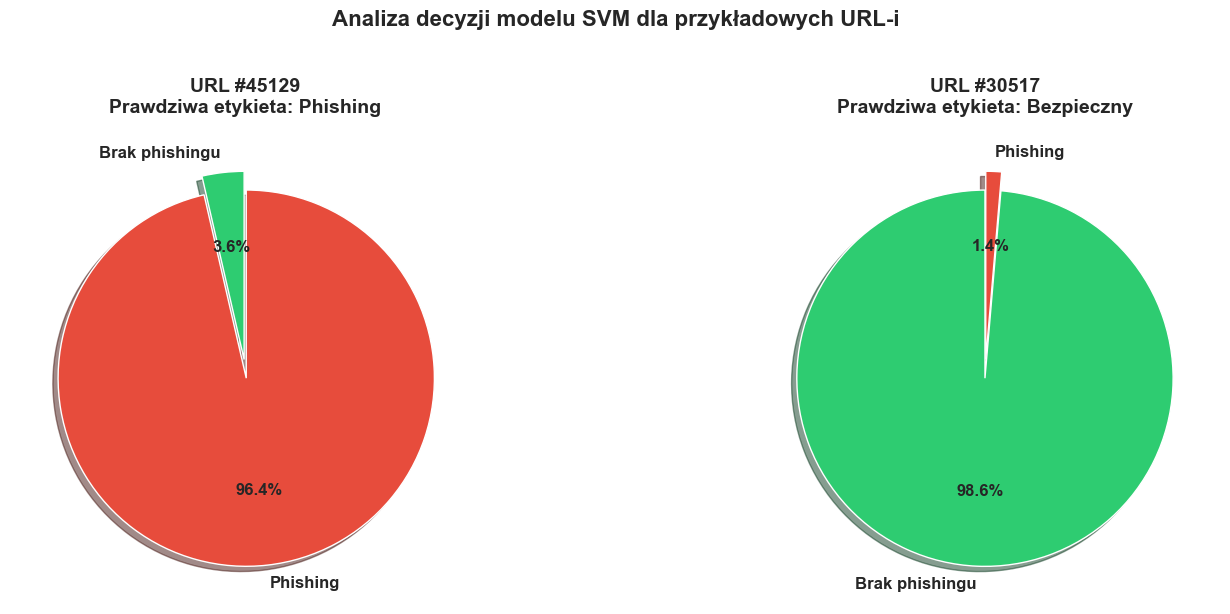


✅ Wizualizacja predykcji dla przykładowych URL-i zapisana


In [ ]:
dataset_name = 'Zoptymalizowany zbiór'
model = results_for_datasets[dataset_name]['model']
X_test = data_splits[dataset_name]['X_test']
y_test = data_splits[dataset_name]['y_test']
X_test_scaled = data_splits[dataset_name]['X_test_scaled']
scaler = data_splits[dataset_name]['scaler']

phishing_idx = y_test[y_test == 1].index[0]
safe_idx = y_test[y_test == 0].index[0]

examples = [
    {'idx': phishing_idx, 'label': 'Phishing', 'color': '#ff7f0e'},
    {'idx': safe_idx, 'label': 'Bezpieczny', 'color': '#1f77b4'}
]

print("="*80)
print("ANALIZA ŚCIEŻKI DECYZYJNEJ DLA PRZYKŁADOWYCH URL-I")
print("="*80)

def create_example_url_from_features(feature_dict):
    """
    Tworzy przykładowy URL na podstawie wartości cech
    """
    length_url = int(feature_dict.get('length_url', 50))
    qty_hyphen_url = int(feature_dict.get('qty_hyphen_url', 0))
    qty_slash_url = int(feature_dict.get('qty_slash_url', 3))
    qty_questionmark_url = int(feature_dict.get('qty_questionmark_url', 0))
    qty_equal_url = int(feature_dict.get('qty_equal_url', 0))
    domain_length = int(feature_dict.get('domain_length', 15))

    protocol = "https://"

    domain_base = "example"
    if qty_hyphen_url > 0:
        domain_base = "ex-ample"

    tld = ".com"

    domain = domain_base + tld

    if qty_slash_url > 3:
        path = "/page/" + "sub/" * (qty_slash_url - 4) + "file.html"
    else:
        path = "/page/file.html"

    params = ""
    if qty_questionmark_url > 0:
        params = "?id=123"
        if qty_equal_url > 1:
            params += "&param=value"

    example_url = protocol + domain + path + params

    return example_url

for example in examples:
    idx = example['idx']
    true_label = example['label']

    sample = X_test.loc[idx:idx]
    sample_scaled = X_test_scaled[X_test.index.get_loc(idx):X_test.index.get_loc(idx)+1]

    prediction = model.predict(sample_scaled)[0]
    prediction_proba = model.predict_proba(sample_scaled)[0]
    predicted_label = 'Phishing' if prediction == 1 else 'Bezpieczny'

    print(f"\n{'='*80}")
    print(f"URL #{idx} - Prawdziwa etykieta: {true_label}")
    print(f"{'='*80}")
    print(f"Predykcja modelu SVM: {predicted_label}")
    print(f"Prawdopodobieństwo:")
    print(f"  • Bezpieczny: {prediction_proba[0]:.4f} ({prediction_proba[0]*100:.2f}%)")
    print(f"  • Phishing: {prediction_proba[1]:.4f} ({prediction_proba[1]*100:.2f}%)")

    decision_function = model.decision_function(sample_scaled)[0]
    print(f"\nFunkcja decyzyjna SVM: {decision_function:.4f}")
    print(f"  • Wartość > 0: klasyfikacja jako Phishing")
    print(f"  • Wartość < 0: klasyfikacja jako Bezpieczny")
    print(f"  • Im większa wartość bezwzględna, tym większa pewność modelu")

    print(f"\nWszystkie cechy dla tego URL (indeks #{idx}):")
    feature_values = sample.iloc[0]
    feature_dict = {}

    for col in X_test.columns:
        readable_name = get_readable_name(col)
        value = feature_values[col]
        feature_dict[col] = value
        print(f"  • {readable_name:50s}: {value:.4f}")

    example_url = create_example_url_from_features(feature_dict)
    print(f"\n{'='*40}")
    print(f"PRZYKŁADOWY URL PASUJĄCY DO STATYSTYK:")
    print(f"{example_url}")
    print(f"{'='*40}")

    print(f"\nTop 10 najważniejszych cech (według wartości bezwzględnej):")
    feature_names_readable = [get_readable_name(col) for col in X_test.columns]

    sorted_features = sorted(
        zip(feature_names_readable, feature_values),
        key=lambda x: abs(x[1]),
        reverse=True
    )[:10]

    for feat_name, feat_val in sorted_features:
        print(f"  • {feat_name}: {feat_val:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Analiza decyzji modelu SVM dla przykładowych URL-i',
             fontsize=16, fontweight='bold', y=1.02)

for idx, example in enumerate(examples):
    sample_idx = example['idx']
    label = example['label']

    sample_scaled = X_test_scaled[X_test.index.get_loc(sample_idx):X_test.index.get_loc(sample_idx)+1]
    prediction_proba = model.predict_proba(sample_scaled)[0]

    sizes = [prediction_proba[0] * 100, prediction_proba[1] * 100]
    labels_pie = ['Brak phishingu', 'Phishing']
    explode = (0.05, 0.05)
    colors_pie = ['#2ecc71', '#e74c3c']

    axes[idx].pie(sizes, explode=explode, labels=labels_pie, colors=colors_pie,
                  autopct='%1.1f%%', shadow=True, startangle=90,
                  textprops={'fontsize': 12, 'fontweight': 'bold'})
    axes[idx].set_title(f'URL #{sample_idx}\nPrawdziwa etykieta: {label}',
                       fontweight='bold', fontsize=14, pad=15)

plt.tight_layout()
plt.savefig(f'{PLOTS_DIR}/svm_prediction_examples.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✅ Wizualizacja predykcji dla przykładowych URL-i zapisana")

## 7.1b. Wizualizacja architektury SVM


Obliczanie permutation importance dla architektury Pełny zbiór...


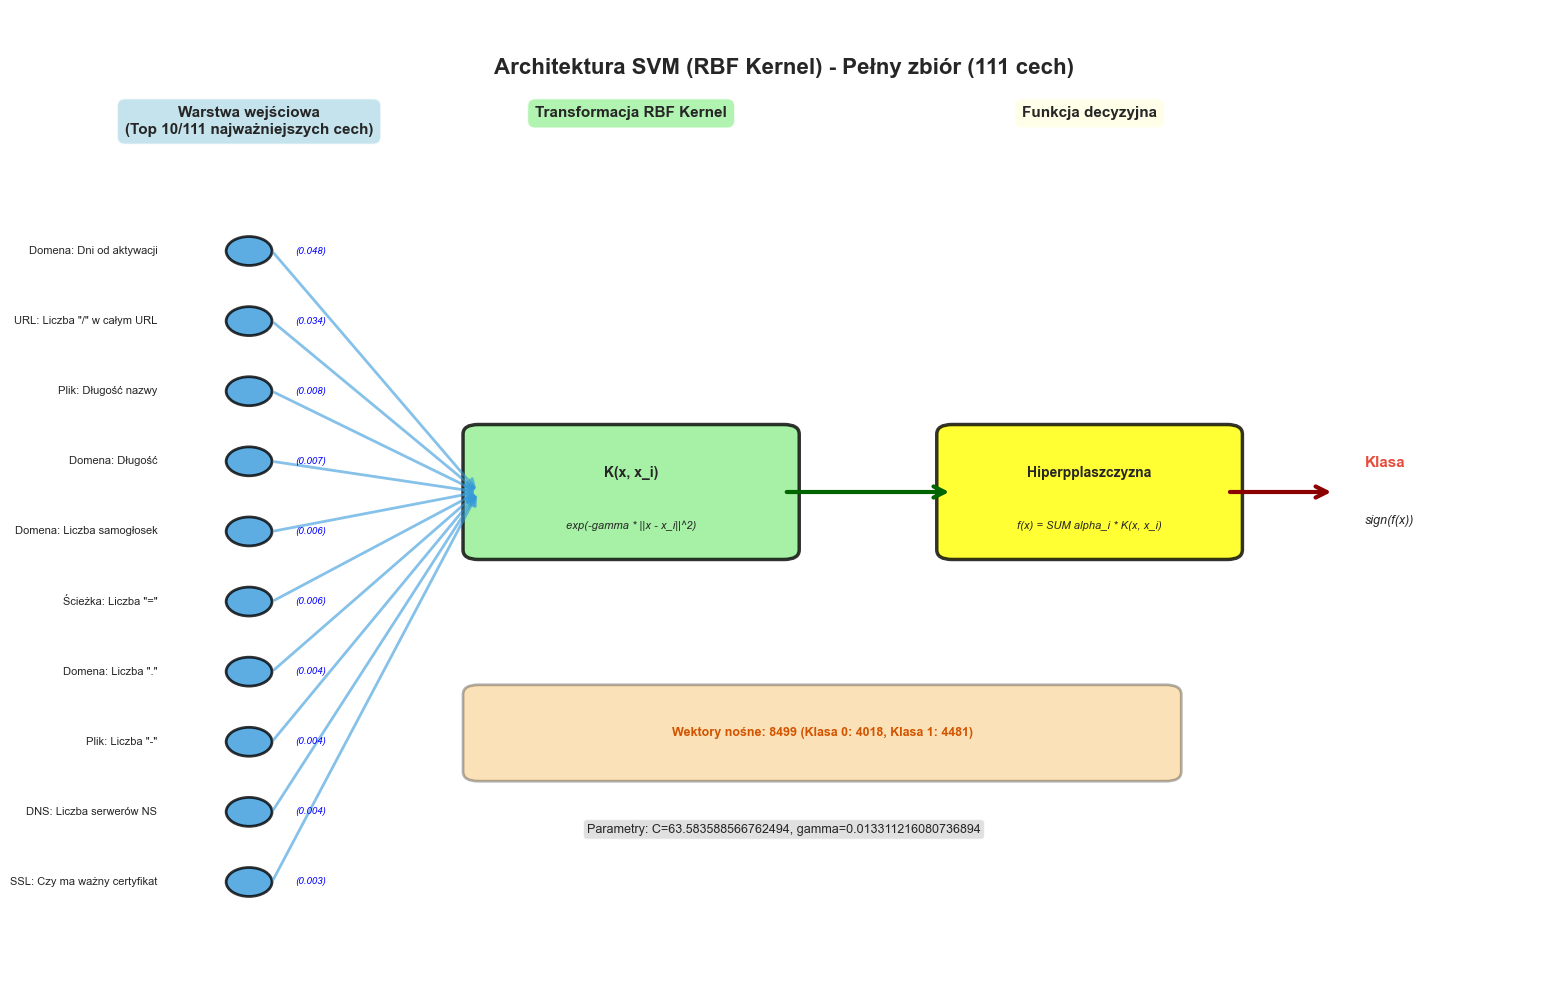

Obliczanie permutation importance dla architektury Zoptymalizowany zbiór...


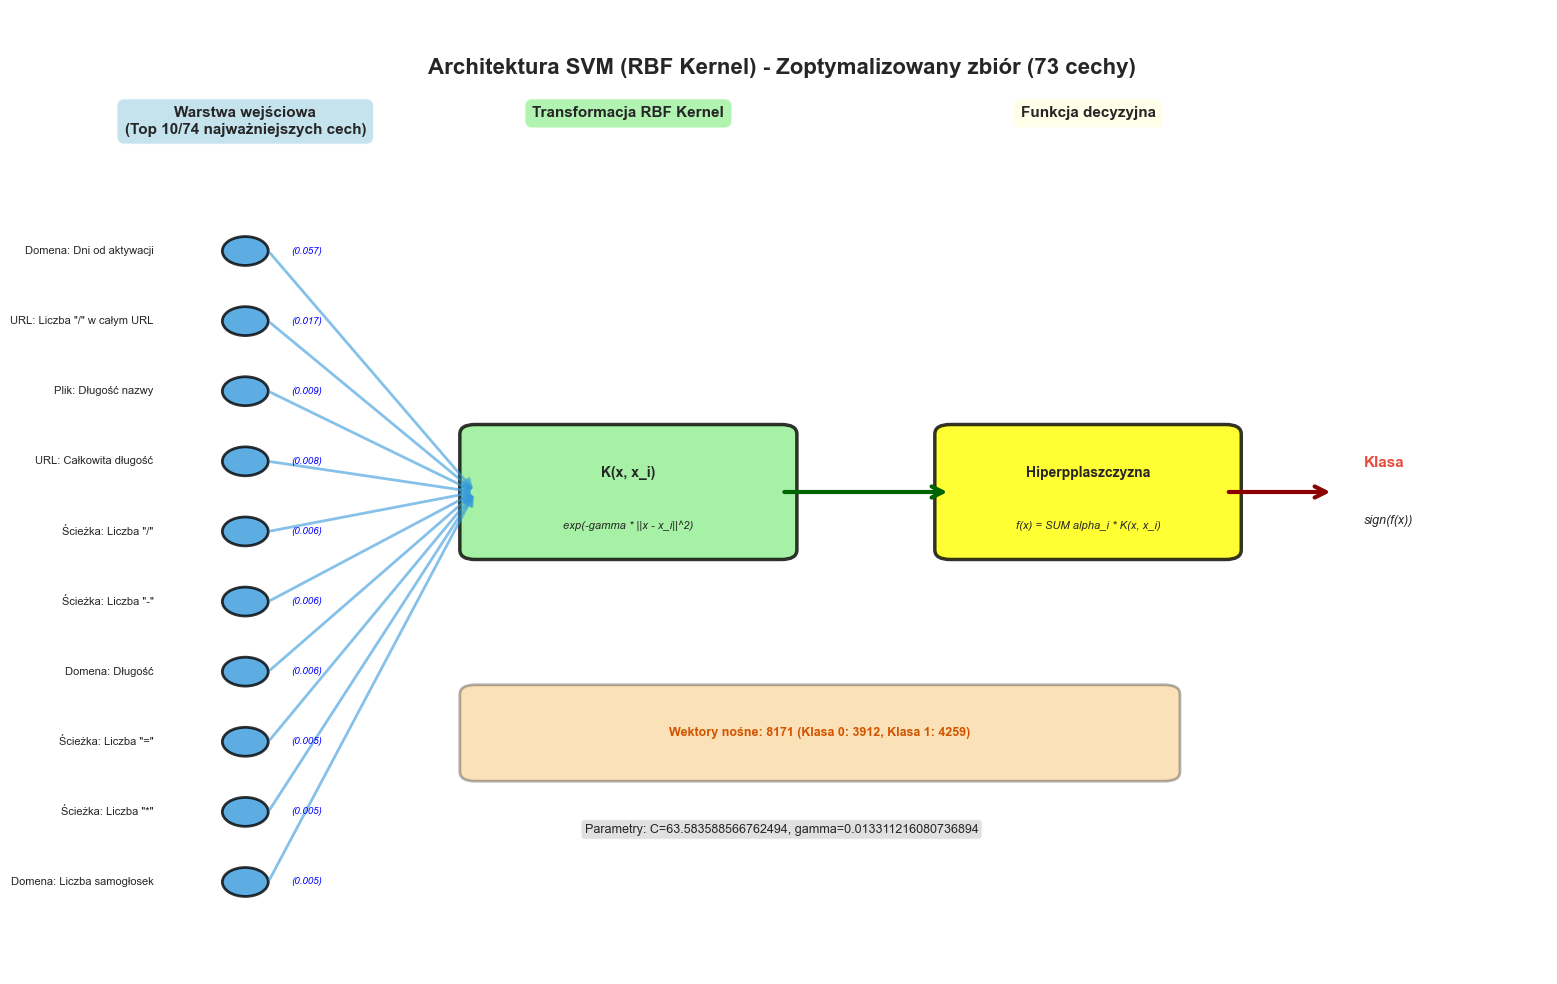

✅ Wizualizacja architektury SVM zapisana


In [20]:
dataset_names = ['Pełny zbiór', 'Zoptymalizowany zbiór']
dataset_display = ['Pełny zbiór (111 cech)', 'Zoptymalizowany zbiór (73 cechy)']

for idx, dataset_name in enumerate(dataset_names):
    model = results_for_datasets[dataset_name]['model']
    X_train = data_splits[dataset_name]['X']
    X_train_scaled = data_splits[dataset_name]['X_train_scaled']
    y_train = data_splits[dataset_name]['y_train']
    total_features = len(X_train.columns)

    if hasattr(model, 'kernel') and model.kernel == 'linear':
        feature_importance_values = np.abs(model.coef_[0])
        kernel_display = 'Linear Kernel'
        kernel_formula = 'K(x, x_i) = x^T * x_i'
    else:
        print(f"Obliczanie permutation importance dla architektury {dataset_name}...")

        if len(X_train_scaled) > 5000:
            from sklearn.model_selection import train_test_split
            X_sample, _, y_sample, _ = train_test_split(
                X_train_scaled, y_train,
                train_size=5000,
                random_state=42,
                stratify=y_train
            )
        else:
            X_sample, y_sample = X_train_scaled, y_train

        from sklearn.inspection import permutation_importance
        perm_importance = permutation_importance(
            model, X_sample, y_sample,
            n_repeats=3,
            random_state=42,
            scoring='roc_auc',
            n_jobs=-1
        )

        feature_importance_values = perm_importance.importances_mean
        kernel_display = 'RBF Kernel'
        kernel_formula = 'exp(-gamma * ||x - x_i||^2)'

    feature_importance_df = pd.DataFrame({
        'Cecha': [get_readable_name(col) for col in X_train.columns],
        'Ważność': feature_importance_values
    }).sort_values('Ważność', ascending=False)

    top_n = 10
    top_features = feature_importance_df.head(top_n)

    fig, ax = plt.subplots(figsize=(16, 10))
    ax.set_xlim(0, 10)
    ax.set_ylim(0, 10)
    ax.axis('off')

    input_layer_x = 1.5
    input_spacing = 8 / (top_n + 1)

    ax.text(5, 9.5, f'Architektura SVM ({kernel_display}) - {dataset_display[idx]}',
            ha='center', va='top', fontsize=16, fontweight='bold')

    ax.text(input_layer_x, 9, f'Warstwa wejściowa\n(Top {top_n}/{total_features} najważniejszych cech)',
            ha='center', va='top', fontsize=11, fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.5', facecolor='lightblue', alpha=0.7))

    input_nodes = []
    for i, (_, row) in enumerate(top_features.iterrows()):
        y_pos = 7.5 - i * input_spacing
        color = '#3498db'

        circle = Circle((input_layer_x, y_pos), 0.15,
                       facecolor=color, edgecolor='black', linewidth=2, alpha=0.8)
        ax.add_patch(circle)
        input_nodes.append((input_layer_x, y_pos))

        feature_text = f"{row['Cecha']}"
        ax.text(input_layer_x - 0.6, y_pos, feature_text,
               ha='right', va='center', fontsize=8)

        ax.text(input_layer_x + 0.3, y_pos, f"({row['Ważność']:.3f})",
               ha='left', va='center', fontsize=7, style='italic', color='blue')

    kernel_x = 4
    kernel_y = 5

    ax.text(kernel_x, 9, f'Transformacja {kernel_display}', ha='center', va='top',
           fontsize=11, fontweight='bold', bbox=dict(boxstyle='round,pad=0.5',
           facecolor='lightgreen', alpha=0.7))

    kernel_box = FancyBboxPatch((kernel_x - 1.0, kernel_y - 0.6), 2.0, 1.2,
                               boxstyle="round,pad=0.1",
                               facecolor='lightgreen', edgecolor='black', linewidth=2.5, alpha=0.8)
    ax.add_patch(kernel_box)

    ax.text(kernel_x, kernel_y + 0.2, 'K(x, x_i)', ha='center', va='center',
           fontsize=10, fontweight='bold')
    ax.text(kernel_x, kernel_y - 0.3, kernel_formula,
           ha='center', va='top', fontsize=8, style='italic')

    for inp_x, inp_y in input_nodes:
        arrow = FancyArrowPatch((inp_x + 0.15, inp_y), (kernel_x - 1.0, kernel_y),
                               arrowstyle='->', mutation_scale=15,
                               color='#3498db', linewidth=2, alpha=0.6)
        ax.add_patch(arrow)

    decision_x = 7
    decision_y = 5

    ax.text(decision_x, 9, 'Funkcja decyzyjna', ha='center', va='top',
           fontsize=11, fontweight='bold', bbox=dict(boxstyle='round,pad=0.5',
           facecolor='lightyellow', alpha=0.7))

    decision_box = FancyBboxPatch((decision_x - 0.9, decision_y - 0.6), 1.8, 1.2,
                                 boxstyle="round,pad=0.1",
                                 facecolor='yellow', edgecolor='black', linewidth=2.5, alpha=0.8)
    ax.add_patch(decision_box)

    ax.text(decision_x, decision_y + 0.2, 'Hiperpplaszczyzna', ha='center', va='center',
           fontsize=10, fontweight='bold')
    ax.text(decision_x, decision_y - 0.3, 'f(x) = SUM alpha_i * K(x, x_i)',
           ha='center', va='top', fontsize=8, style='italic')

    arrow = FancyArrowPatch((kernel_x + 1.0, kernel_y), (decision_x - 0.9, decision_y),
                           arrowstyle='->', mutation_scale=20,
                           color='darkgreen', linewidth=3)
    ax.add_patch(arrow)

    output_y = 5
    output_x = decision_x + 1.2

    ax.text(output_x + 0.6, output_y + 0.3, 'Klasa', ha='left', va='center',
           fontsize=11, fontweight='bold', color='#e74c3c')
    ax.text(output_x + 0.6, output_y - 0.3, 'sign(f(x))', ha='left', va='center',
           fontsize=9, style='italic')

    arrow = FancyArrowPatch((decision_x + 0.9, decision_y), (output_x + 0.4, output_y),
                           arrowstyle='->', mutation_scale=20,
                           color='darkred', linewidth=3)
    ax.add_patch(arrow)

    support_vector_y = 2.5
    sv_box = FancyBboxPatch((3, support_vector_y - 0.4), 4.5, 0.8,
                           boxstyle="round,pad=0.1",
                           facecolor='#f39c12', edgecolor='black', linewidth=2, alpha=0.3)
    ax.add_patch(sv_box)

    n_support = model.n_support_
    total_sv = sum(n_support)
    ax.text(5.25, support_vector_y, f'Wektory nośne: {total_sv} (Klasa 0: {n_support[0]}, Klasa 1: {n_support[1]})',
           ha='center', va='center', fontsize=9, fontweight='bold', color='#d35400')

    if hasattr(model, 'C') and hasattr(model, 'gamma'):
        param_info = f'Parametry: C={model.C}, gamma={model.gamma}'
    else:
        param_info = 'Parametry modelu niedostępne'

    ax.text(5, 1.5, param_info, ha='center', va='center',
           fontsize=9, bbox=dict(boxstyle='round,pad=0.3', facecolor='lightgray', alpha=0.7))

    plt.tight_layout()
    plt.savefig(f'{PLOTS_DIR}/svm_architecture_{dataset_name.replace(" ", "_")}.png',
                dpi=300, bbox_inches='tight')
    plt.show()

print("✅ Wizualizacja architektury SVM zapisana")

## 7.2. Wpływ rozmiaru zbioru uczącego na skuteczność modelu


Optymalizacja: Używanie 15000 próbek dla krzywej uczenia (Pełny zbiór)
Optymalizacja: Używanie 15000 próbek dla krzywej uczenia (Zoptymalizowany zbiór)
Optymalizacja: Używanie 15000 próbek dla krzywej uczenia (Zoptymalizowany zbiór)


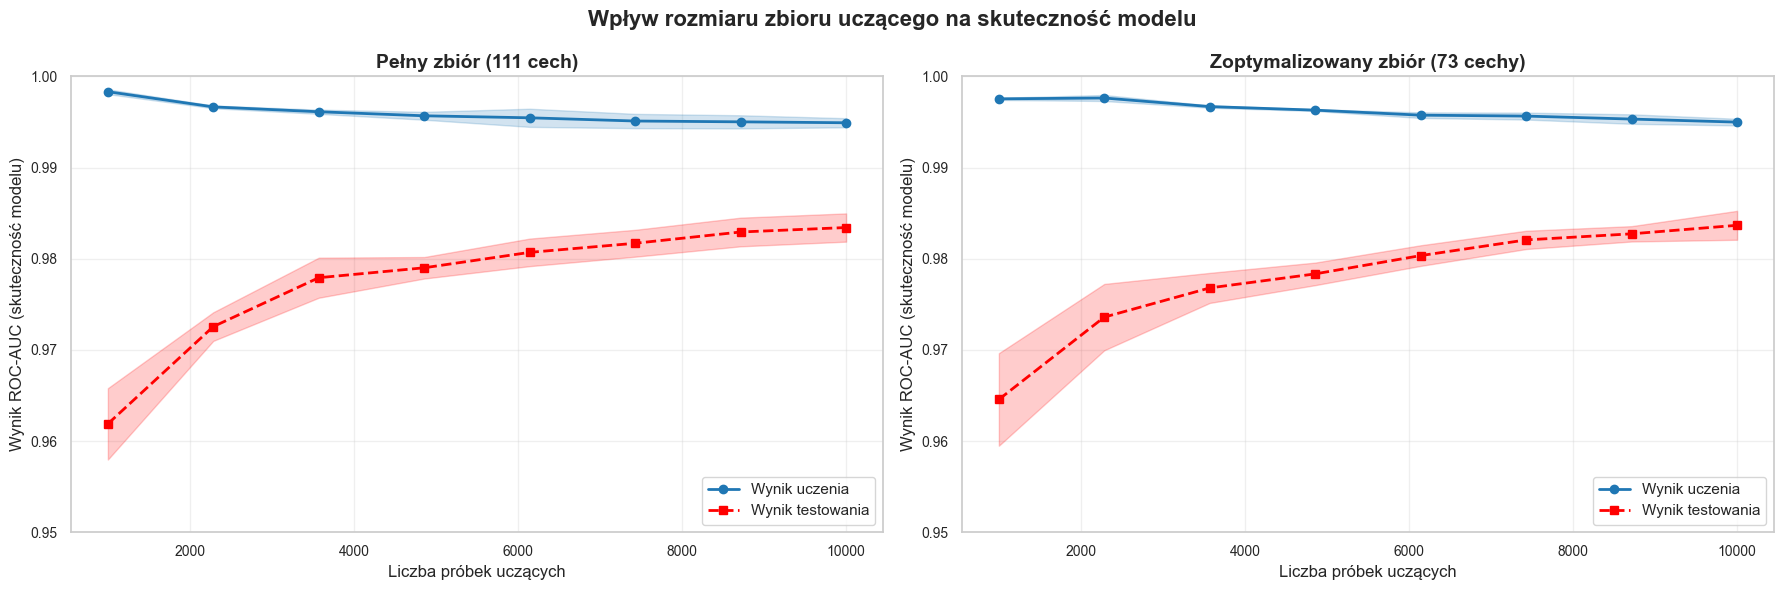

✅ Krzywe uczenia zapisane


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
fig.suptitle('Wpływ rozmiaru zbioru uczącego na skuteczność modelu', fontsize=16, fontweight='bold')

dataset_names = ['Pełny zbiór', 'Zoptymalizowany zbiór']
display_names = ['Pełny zbiór (111 cech)', 'Zoptymalizowany zbiór (73 cechy)']

LEARNING_CURVE_SAMPLE_SIZE = 15000

for idx, dataset_name in enumerate(dataset_names):
    model = results_for_datasets[dataset_name]['model']
    X_train_scaled = data_splits[dataset_name]['X_train_scaled']
    y_train = data_splits[dataset_name]['y_train']

    if len(X_train_scaled) > LEARNING_CURVE_SAMPLE_SIZE:
        print(f"Optymalizacja: Używanie {LEARNING_CURVE_SAMPLE_SIZE} próbek dla krzywej uczenia ({dataset_name})")
        X_sample, _, y_sample, _ = train_test_split(
            X_train_scaled, y_train,
            train_size=LEARNING_CURVE_SAMPLE_SIZE,
            random_state=42,
            stratify=y_train
        )
    else:
        X_sample, y_sample = X_train_scaled, y_train

    train_sizes, train_scores, val_scores = learning_curve(
        model, X_sample, y_sample,
        cv=3,
        scoring='roc_auc',
        n_jobs=-1,
        train_sizes=np.linspace(0.1, 1.0, 8),
        random_state=42
    )

    train_mean = np.mean(train_scores, axis=1)
    train_std = np.std(train_scores, axis=1)
    val_mean = np.mean(val_scores, axis=1)
    val_std = np.std(val_scores, axis=1)

    axes[idx].plot(train_sizes, train_mean, label='Wynik uczenia', color='#1f77b4', linewidth=2, marker='o')
    axes[idx].fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.2, color='#1f77b4')

    axes[idx].plot(train_sizes, val_mean, label='Wynik testowania', color='red', linewidth=2, marker='s', linestyle='--')
    axes[idx].fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.2, color='red')

    axes[idx].set_xlabel('Liczba próbek uczących', fontsize=12)
    axes[idx].set_ylabel('Wynik ROC-AUC (skuteczność modelu)', fontsize=12)
    axes[idx].set_title(f'{display_names[idx]}', fontweight='bold', fontsize=14)
    axes[idx].legend(loc='lower right', fontsize=11)
    axes[idx].grid(True, alpha=0.3)
    axes[idx].set_ylim([0.95, 1.0])

plt.tight_layout()
plt.savefig(f'{PLOTS_DIR}/svm_learning_curves.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Krzywe uczenia zapisane")

## 7.3. Wpływ regularyzacji (parametr C) na skuteczność modelu


Optymalizacja: Używanie 15000 próbek dla krzywej walidacji (Pełny zbiór)
Optymalizacja: Używanie 15000 próbek dla krzywej walidacji (Zoptymalizowany zbiór)
Optymalizacja: Używanie 15000 próbek dla krzywej walidacji (Zoptymalizowany zbiór)


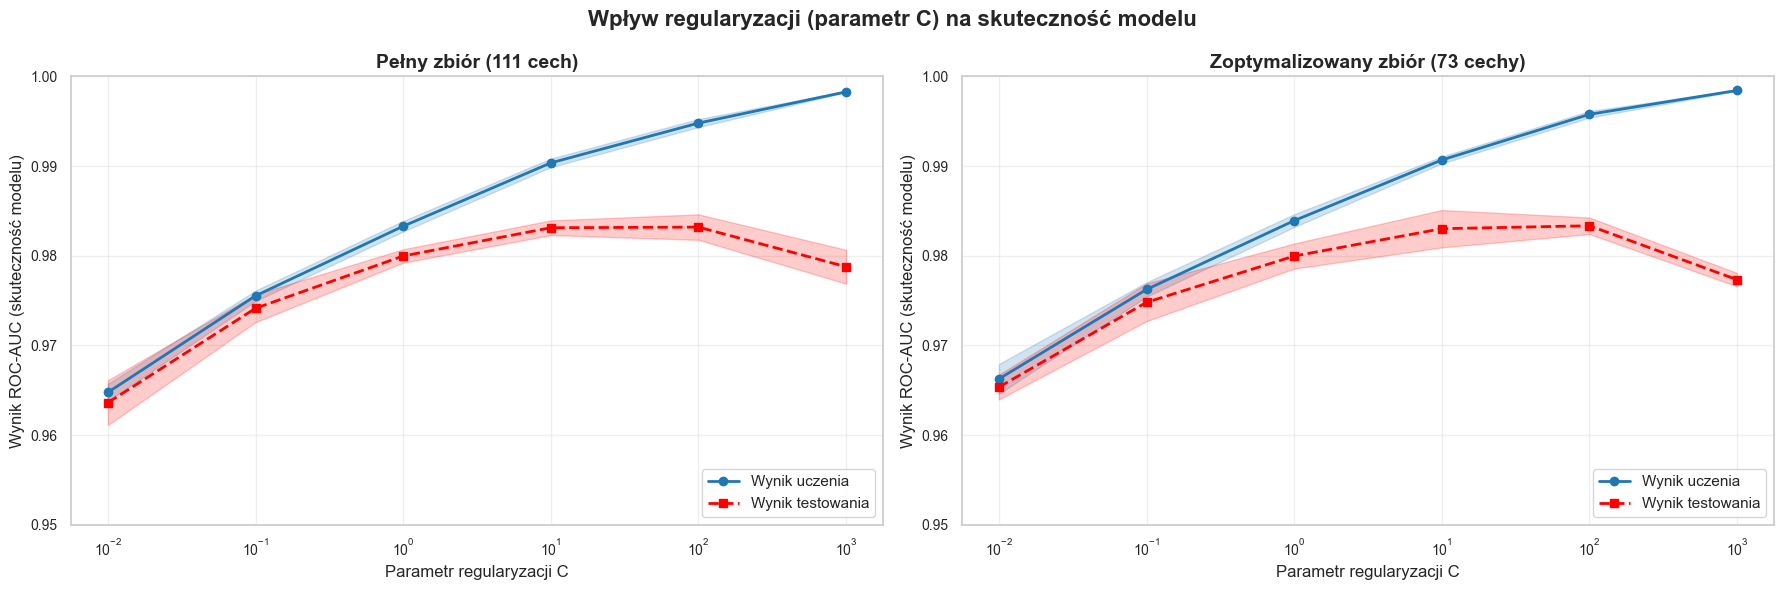

✅ Krzywe walidacyjne zapisane


In [24]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
fig.suptitle('Wpływ regularyzacji (parametr C) na skuteczność modelu', fontsize=16, fontweight='bold')

dataset_names_internal = ['Pełny zbiór (111 cech)', 'Zoptymalizowany zbiór (73 cechy)']
dataset_keys = ['Pełny zbiór', 'Zoptymalizowany zbiór']
param_range = np.logspace(-2, 3, 6)

VALIDATION_CURVE_SAMPLE_SIZE = 15000

for idx, dataset_key in enumerate(dataset_keys):
    X_train_data = data_splits[dataset_key]['X_train_scaled']
    y_train = data_splits[dataset_key]['y_train']

    if len(X_train_data) > VALIDATION_CURVE_SAMPLE_SIZE:
        print(f"Optymalizacja: Używanie {VALIDATION_CURVE_SAMPLE_SIZE} próbek dla krzywej walidacji ({dataset_key})")
        X_sample, _, y_sample, _ = train_test_split(
            X_train_data, y_train,
            train_size=VALIDATION_CURVE_SAMPLE_SIZE,
            random_state=42,
            stratify=y_train
        )
    else:
        X_sample, y_sample = X_train_data, y_train

    model_base = SVC(kernel='rbf', random_state=42, probability=True)

    train_scores, val_scores = validation_curve(
        model_base, X_sample, y_sample,
        param_name='C',
        param_range=param_range,
        cv=3,
        scoring='roc_auc',
        n_jobs=-1
    )

    train_mean = np.mean(train_scores, axis=1)
    train_std = np.std(train_scores, axis=1)
    val_mean = np.mean(val_scores, axis=1)
    val_std = np.std(val_scores, axis=1)

    axes[idx].semilogx(param_range, train_mean, label='Wynik uczenia', color='#1f77b4', linewidth=2, marker='o')
    axes[idx].fill_between(param_range, train_mean - train_std, train_mean + train_std, alpha=0.2, color='#1f77b4')

    axes[idx].semilogx(param_range, val_mean, label='Wynik testowania', color='red', linewidth=2, marker='s', linestyle='--')
    axes[idx].fill_between(param_range, val_mean - val_std, val_mean + val_std, alpha=0.2, color='red')

    axes[idx].set_xlabel('Parametr regularyzacji C', fontsize=12)
    axes[idx].set_ylabel('Wynik ROC-AUC (skuteczność modelu)', fontsize=12)
    axes[idx].set_title(f'{dataset_names_internal[idx]}', fontweight='bold', fontsize=14)
    axes[idx].legend(loc='lower right', fontsize=11)
    axes[idx].grid(True, alpha=0.3)
    axes[idx].set_ylim([0.95, 1.0])

plt.tight_layout()
plt.savefig(f'{PLOTS_DIR}/svm_validation_curves.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Krzywe walidacyjne zapisane")

## 7.4. Ważność cech w obu modelach


Obliczanie permutation importance dla Pełny zbiór...
Obliczanie permutation importance dla Zoptymalizowany zbiór...
Obliczanie permutation importance dla Zoptymalizowany zbiór...


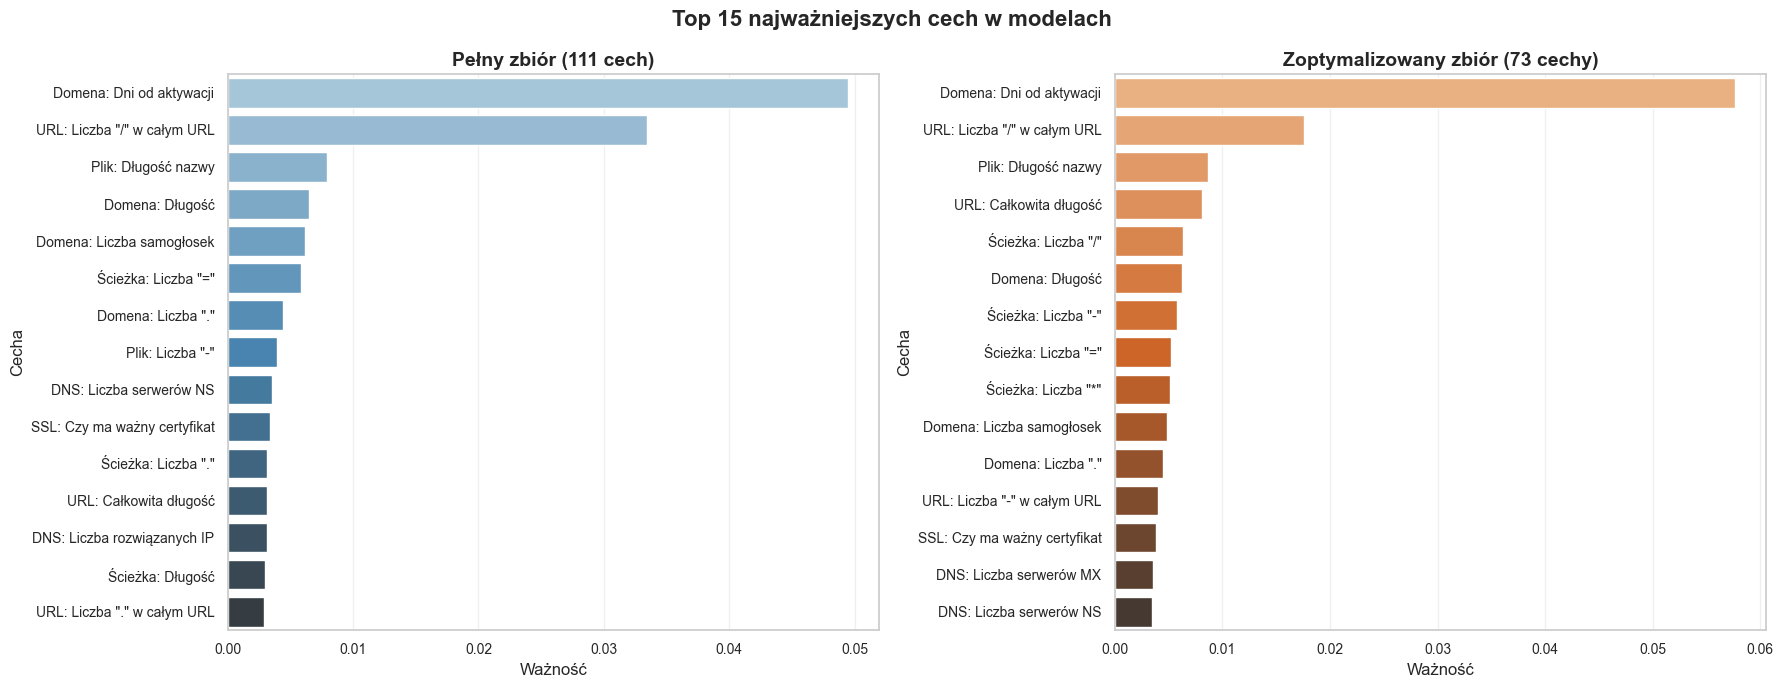

✅ Wizualizacja ważności cech zapisana


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.suptitle('Top 15 najważniejszych cech w modelach', fontsize=16, fontweight='bold')

dataset_names = ['Pełny zbiór', 'Zoptymalizowany zbiór']
dataset_display = ['Pełny zbiór (111 cech)', 'Zoptymalizowany zbiór (73 cechy)']
colors_palette = ['Blues_d', 'Oranges_d']

for idx, dataset_name in enumerate(dataset_names):
    model = results_for_datasets[dataset_name]['model']
    X = data_splits[dataset_name]['X']
    X_train_scaled = data_splits[dataset_name]['X_train_scaled']
    y_train = data_splits[dataset_name]['y_train']

    if hasattr(model, 'kernel') and model.kernel == 'linear':
        feature_importance_values = np.abs(model.coef_[0])
        importance_label = '|Współczynnik|'
    else:
        from sklearn.inspection import permutation_importance

        print(f"Obliczanie permutation importance dla {dataset_name}...")

        if len(X_train_scaled) > 5000:
            from sklearn.model_selection import train_test_split
            X_sample, _, y_sample, _ = train_test_split(
                X_train_scaled, y_train,
                train_size=5000,
                random_state=42,
                stratify=y_train
            )
        else:
            X_sample, y_sample = X_train_scaled, y_train

        perm_importance = permutation_importance(
            model, X_sample, y_sample,
            n_repeats=5,
            random_state=42,
            scoring='roc_auc',
            n_jobs=-1
        )

        feature_importance_values = perm_importance.importances_mean
        importance_label = 'Ważność'

    feature_importance = pd.DataFrame({
        'Cecha': [get_readable_name(col) for col in X.columns],
        'Ważność': feature_importance_values
    }).sort_values('Ważność', ascending=False)

    top_features = feature_importance.head(15)

    sns.barplot(x='Ważność', y='Cecha', data=top_features,
                palette=colors_palette[idx], ax=axes[idx])
    axes[idx].set_xlabel(importance_label, fontsize=12)
    axes[idx].set_ylabel('Cecha', fontsize=12)
    axes[idx].set_title(f'{dataset_display[idx]}', fontweight='bold', fontsize=14)
    axes[idx].grid(True, alpha=0.3, axis='x')

plt.tight_layout()
plt.savefig(f'{PLOTS_DIR}/svm_feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Wizualizacja ważności cech zapisana")

## 8. Zapis modeli


In [21]:
for dataset_name in ['Pełny zbiór', 'Zoptymalizowany zbiór']:
    file_suffix = 'full' if dataset_name == 'Pełny zbiór' else 'optimized'

    model_data = {
        'model': results_for_datasets[dataset_name]['model'],
        'scaler': data_splits[dataset_name]['scaler'],
        'feature_names': data_splits[dataset_name]['X'].columns.tolist(),
        'best_params': results_for_datasets[dataset_name]['best_params'],
        'metrics': {
            'accuracy': evaluation_results[dataset_name]['accuracy'],
            'precision': evaluation_results[dataset_name]['precision'],
            'recall': evaluation_results[dataset_name]['recall'],
            'f1': evaluation_results[dataset_name]['f1'],
            'auc_roc': evaluation_results[dataset_name]['auc_roc'],
            'cv_auc_mean': evaluation_results[dataset_name]['cv_mean'],
            'cv_auc_std': evaluation_results[dataset_name]['cv_std']
        }
    }

    model_path = f'{MODELS_DIR}/svm_model_{file_suffix}.pkl'
    with open(model_path, 'wb') as f:
        pickle.dump(model_data, f)
    print(f"✓ Model zapisany: {model_path}")

    scaler_path = f'{MODELS_DIR}/svm_scaler_{file_suffix}.pkl'
    with open(scaler_path, 'wb') as f:
        pickle.dump(data_splits[dataset_name]['scaler'], f)
    print(f"✓ Scaler zapisany: {scaler_path}")

print(f"\n{'='*80}")
print("PODSUMOWANIE KOŃCOWE")
print(f"{'='*80}")

for dataset_name in ['Pełny zbiór', 'Zoptymalizowany zbiór']:
    print(f"\n{dataset_name.upper()}:")
    print(f"  Liczba cech: {len(data_splits[dataset_name]['X'].columns)}")
    print(f"  Dokładność: {evaluation_results[dataset_name]['accuracy']:.4f}")
    print(f"  F1-Score: {evaluation_results[dataset_name]['f1']:.4f}")
    print(f"  AUC-ROC: {evaluation_results[dataset_name]['auc_roc']:.4f}")
    print(f"  Czas trenowania: {results_for_datasets[dataset_name]['training_time']:.2f}s")

print(f"\n✅ Wszystkie modele i wizualizacje zostały zapisane!")
print(f"Wizualizacje zapisane w: {PLOTS_DIR}/")
print(f"Modele zapisane w: {MODELS_DIR}/")


✓ Model zapisany: ../models/svm/svm_model_full.pkl
✓ Scaler zapisany: ../models/svm/svm_scaler_full.pkl
✓ Model zapisany: ../models/svm/svm_model_optimized.pkl
✓ Scaler zapisany: ../models/svm/svm_scaler_optimized.pkl

PODSUMOWANIE KOŃCOWE

PEŁNY ZBIÓR:
  Liczba cech: 111
  Dokładność: 0.9603
  F1-Score: 0.9423
  AUC-ROC: 0.9884
  Czas trenowania: 615.01s

ZOPTYMALIZOWANY ZBIÓR:
  Liczba cech: 74
  Dokładność: 0.9602
  F1-Score: 0.9427
  AUC-ROC: 0.9878
  Czas trenowania: 602.56s

✅ Wszystkie modele i wizualizacje zostały zapisane!
Wizualizacje zapisane w: ../static/plots/svm/
Modele zapisane w: ../models/svm/
